# v4 · Near-market return with a smaller drawdown

Design: [docs/v4_design_note.md](../docs/v4_design_note.md), written before this notebook.

**Question:** can a weekly Buy / Hold / Sell model keep most of the S&P 500's return while cutting its worst losses?
**Target:** at least 85% of buy-and-hold's annual return, the smallest maximum drawdown, and at least 70% of the time invested.

**Optimal action for the next 5 trading days** (open t+1 → open t+6): **Sell** if the return is below −2% (a large loss), **Buy** if above +1%, otherwise **Hold**.

**Weekly decision:** after the week's last close, go to cash for the week if the calibrated P(Sell) ≥ τ; otherwise stay invested. The decision is re-made every week, and fills at the next open. Cash earns T-bills.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import config, v2, v3, weekly
from src.data import load_snapshot
from src.dataset import build_dataset
from src.evaluate import classification_metrics
from src.features import FEATURE_COLS
from src.models import tune
from src.split import get_segments, make_cv

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.4f}".format)
OUT = config.OUTPUT_DIR / "v4"; (OUT / "figures").mkdir(parents=True, exist_ok=True)
SELL_THR, BUY_THR, TAUS = -0.02, 0.01, [0.20, 0.30, 0.40]

raw = load_snapshot(); px = raw[["Open", "Close"]]
rf = v2.load_tbill_daily(raw.index)
ds = build_dataset(raw, label_kind="open", buy_thr=BUY_THR, sell_thr=SELL_THR)
train = get_segments(ds, gap=config.V2_GAP)["train"]
print("class share, training 2010–2020:", train["label"].map(config.CLASS_NAMES).value_counts(normalize=True).round(3).to_dict())

class share, training 2010–2020: {'Hold': 0.533, 'Buy': 0.35, 'Sell': 0.116}


## 1 · Tune each model on 2010–2020 (time-series CV, gap 6, log loss)

In [2]:
cv = make_cv(gap=config.V2_GAP)
PARAMS = {}
for name in ["LR", "RF", "HGB"]:
    s = tune(name, train[FEATURE_COLS], train["label"].astype(int), cv, n_iter=20, scoring="neg_log_loss")
    PARAMS[name] = {k: (float(v) if isinstance(v, (np.floating, float)) else v) for k, v in s.best_params_.items()}
    print(name, "CV log loss", round(-s.best_score_, 4), PARAMS[name])

LR CV log loss 1.025 {'clf__C': 0.05342937261279776}


RF CV log loss 1.0104 {'clf__max_depth': None, 'clf__max_features': 0.5, 'clf__min_samples_leaf': 54}


HGB CV log loss 1.014 {'clf__l2_regularization': 0.17336465350777208, 'clf__learning_rate': 0.032268708256236636, 'clf__max_depth': 3, 'clf__max_iter': 51, 'clf__min_samples_leaf': 153}


## 2 · Development walk-forward 2013–2022 and selection

In [3]:
def weekly_held(p_sell, tau):
    actions = pd.Series(np.where(p_sell >= tau, -1, 1), index=p_sell.index)
    return v2.held_from_positions(weekly.weekly_positions_from_actions(actions, start=1), start=1)

def run(held, prices, rfs):
    sim = v2.simulate(held, prices.loc[held.index], rfs.loc[held.index])
    return sim, v2.summarize(sim, held, rfs.loc[held.index], "")

DEV = list(range(2013, 2023))
PROBA = {m: v3.walk_forward_proba(ds, "C2", DEV, PARAMS[m], m) for m in PARAMS}
days = PROBA["LR"].index
bh_sim, bh = run(v2.buy_and_hold_held(days), px, rf)
rows = []
for m, p in PROBA.items():
    for tau in TAUS:
        _, s = run(weekly_held(p[-1], tau), px, rf)
        rows.append({"model": m, "tau": tau, "cagr": s["cagr"], "share_of_bh_return": s["cagr"] / bh["cagr"],
                     "max_drawdown": s["max_drawdown"], "sharpe": s["sharpe_excess"], "time_invested": s["exposure"],
                     "round_trips": s["round_trips"], "final_value": s["final_value"]})
dev = pd.DataFrame(rows)
print("Buy & Hold 2013–22:", {k: bh[k] for k in ["final_value", "cagr", "max_drawdown", "sharpe_excess"]})
display(dev.sort_values("max_drawdown", ascending=False))

elig = dev[(dev["share_of_bh_return"] >= 0.85) & (dev["time_invested"] >= 0.70)]
if len(elig):
    pick = elig.sort_values(["max_drawdown", "sharpe"], ascending=[False, False]).iloc[0]; how = "target met"
else:
    pool = dev[dev["time_invested"] >= 0.70].assign(calmar=lambda d: d["cagr"] / d["max_drawdown"].abs())
    pick = pool.sort_values("calmar", ascending=False).iloc[0]; how = "fallback: highest Calmar (no candidate met 85% of buy-and-hold's return)"
FROZEN = {"version": "v4", "model": pick["model"], "tau": float(pick["tau"]), "params": PARAMS[pick["model"]],
          "label": "next 5 days open→open: Sell < −2%, Buy > +1%, else Hold", "probabilities": "balanced weights + prior correction (C2)",
          "decision": "weekly; cash for the week if P(Sell) ≥ tau, else invested", "selection": how,
          "dev_cagr": float(pick["cagr"]), "dev_max_drawdown": float(pick["max_drawdown"]), "dev_bh_cagr": bh["cagr"],
          "dev_bh_max_drawdown": bh["max_drawdown"], "frozen_before_test": True}
(OUT / "frozen_config.json").write_text(json.dumps(FROZEN, indent=2, default=str))
FROZEN

Buy & Hold 2013–22: {'final_value': 316843.58, 'cagr': 0.1223, 'max_drawdown': -0.3372, 'sharpe_excess': 0.708}


,model,tau,cagr,share_of_bh_return,max_drawdown,sharpe,time_invested,round_trips,final_value
3,RF,0.2000,0.0886,0.7244,-0.2146,0.6330,0.8760,28,"233,519.1600"
6,HGB,0.2000,0.0742,0.6067,-0.2221,0.5430,0.8660,31,"204,488.1000"
7,HGB,0.3000,0.0983,0.8038,-0.2951,0.6130,0.9810,6,"255,239.6900"
4,RF,0.3000,0.0935,0.7645,-0.3106,0.5870,0.9790,5,"244,181.5900"
8,HGB,0.4000,0.1198,0.9796,-0.3372,0.6970,0.9980,2,"309,788.8200"
2,LR,0.4000,0.1104,0.9027,-0.3372,0.6530,0.9940,3,"284,707.3500"
0,LR,0.2000,0.0427,0.3491,-0.3488,0.3200,0.8810,31,"151,911.1600"
1,LR,0.3000,0.0871,0.7122,-0.3489,0.5410,0.9830,6,"230,335.6400"
5,RF,0.4000,0.1093,0.8937,-0.3489,0.6520,0.9980,2,"281,904.9000"


{'version': 'v4',
 'model': 'HGB',
 'tau': 0.4,
 'params': {'clf__l2_regularization': 0.17336465350777208,
  'clf__learning_rate': 0.032268708256236636,
  'clf__max_depth': 3,
  'clf__max_iter': 51,
  'clf__min_samples_leaf': 153},
 'label': 'next 5 days open→open: Sell < −2%, Buy > +1%, else Hold',
 'probabilities': 'balanced weights + prior correction (C2)',
 'decision': 'weekly; cash for the week if P(Sell) ≥ tau, else invested',
 'selection': 'target met',
 'dev_cagr': 0.1198,
 'dev_max_drawdown': -0.3372,
 'dev_bh_cagr': 0.1223,
 'dev_bh_max_drawdown': -0.3372,
 'frozen_before_test': True}

## 3 · Reported periods: 2023–24, the full 2013–2024 walk-forward, and the 2025–26 holdout

In [4]:
M, TAU, P = FROZEN["model"], FROZEN["tau"], FROZEN["params"]
RES, PATHS = {}, {}
def report(label, data, prices, rfs, years, random_n=1000):
    wf = v3.walk_forward_proba(data, "C2", years, P, M)
    held = weekly_held(wf[-1], TAU)
    sim, s = run(held, prices, rfs)
    bsim, b = run(v2.buy_and_hold_held(held.index), prices, rfs)
    pct = None
    if s["round_trips"] > 1 and random_n:
        rand = v2.random_timing_benchmark(held, prices.loc[held.index], rfs.loc[held.index], n=random_n)
        pct = round(float((rand < s["final_value"]).mean()), 3)
    lab = data.loc[held.index, "label"].dropna().astype(int)
    pr = wf.loc[lab.index, config.CLASSES]
    cls = classification_metrics(lab, np.array(config.CLASSES)[pr.to_numpy().argmax(1)], pr.to_numpy())
    RES[label] = {"v4": s, "buy_and_hold": b, "beats_random": pct,
                  "classification": {k: cls[k] for k in ["n", "accuracy", "macro_f1", "recall_Sell", "log_loss"]}}
    PATHS[label] = {"dates": [d.strftime("%Y-%m-%d") for d in held.index], "v4": [round(float(x)) for x in sim["value"]],
                    "bh": [round(float(x)) for x in bsim["value"]]}
    display(pd.DataFrame([dict(s, strategy="v4"), dict(b, strategy="Buy & Hold")]).set_index("strategy"))
    print(label, "| beats random:", pct, "|", RES[label]["classification"])

report("2023–24 test", ds, px, rf, [2023, 2024])
report("2013–24 walk-forward", ds, px, rf, list(range(2013, 2025)), random_n=200)
HOLD = config.ROOT / "data" / "holdout"
raw_h = pd.read_csv(HOLD / "spy_20261013.csv", index_col=0, parse_dates=True)
rf_h = v2.load_tbill_daily(raw_h.index, HOLD / "irx_20261013.csv")
ds_h = build_dataset(raw_h, label_kind="open", buy_thr=BUY_THR, sell_thr=SELL_THR)
report("2025–26 holdout", ds_h, raw_h[["Open", "Close"]], rf_h, [2025, 2026])

,final_value,total_return,cagr,ann_vol,sharpe_excess,max_drawdown,round_trips,exposure,total_fees
strategy,,,,,,,,,
v4,"156,546.2500",0.5655,0.2523,0.1283,1.4300,-0.0997,1,1.0000,99.9000
Buy & Hold,"156,546.2500",0.5655,0.2523,0.1283,1.4300,-0.0997,1,1.0000,99.9000


2023–24 test | beats random: None | {'n': 496, 'accuracy': 0.5645, 'macro_f1': 0.3382, 'recall_Sell': 0.0, 'log_loss': 0.8857}


,final_value,total_return,cagr,ann_vol,sharpe_excess,max_drawdown,round_trips,exposure,total_fees
strategy,,,,,,,,,
v4,"488,154.2800",3.8815,0.1414,0.1664,0.7910,-0.3372,2,0.9980,539.5900
Buy & Hold,"499,270.9200",3.9927,0.1436,0.1670,0.8000,-0.3372,1,1.0000,99.9000


2013–24 walk-forward | beats random: 0.45 | {'n': 3014, 'accuracy': 0.567, 'macro_f1': 0.3593, 'recall_Sell': 0.0, 'log_loss': 0.9115}


,final_value,total_return,cagr,ann_vol,sharpe_excess,max_drawdown,round_trips,exposure,total_fees
strategy,,,,,,,,,
v4,"139,986.2200",0.3999,0.2098,0.1683,0.9860,-0.1876,2,0.9910,284.5800
Buy & Hold,"134,409.7400",0.3441,0.1823,0.1694,0.8440,-0.1876,1,1.0000,99.9000


2025–26 holdout | beats random: 0.494 | {'n': 439, 'accuracy': 0.6059, 'macro_f1': 0.396, 'recall_Sell': 0.025, 'log_loss': 0.8708}


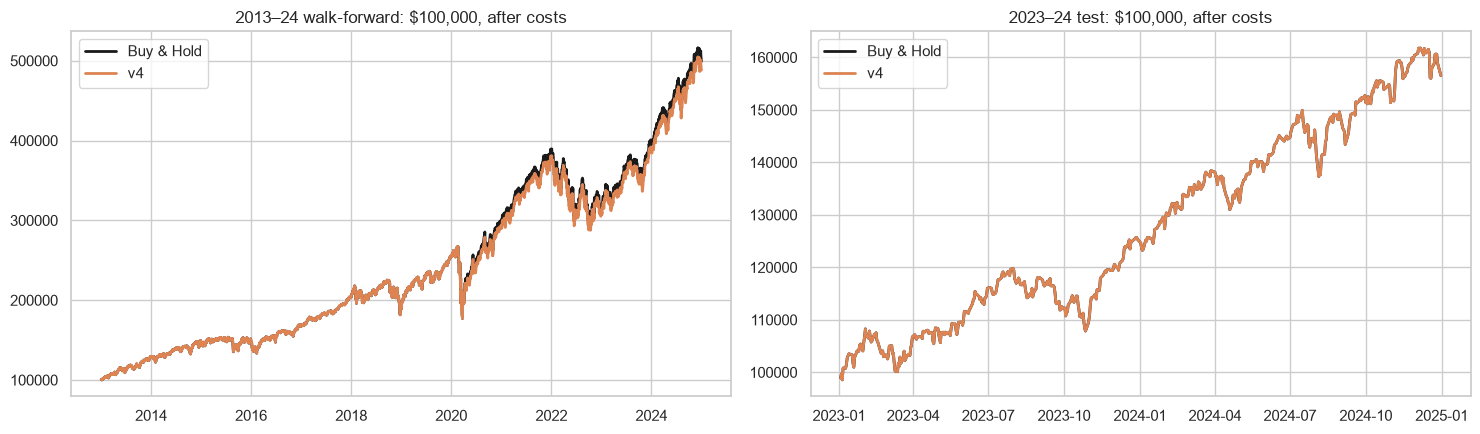

saved outputs/v4/


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for j, k in enumerate(["2013–24 walk-forward", "2023–24 test"]):
    d = pd.to_datetime(PATHS[k]["dates"])
    ax[j].plot(d, PATHS[k]["bh"], color="k", lw=2, label="Buy & Hold")
    ax[j].plot(d, PATHS[k]["v4"], color="C1", lw=2, label="v4")
    ax[j].set_title(f"{k}: $100,000, after costs"); ax[j].legend()
plt.tight_layout(); plt.savefig(OUT / "figures" / "v4_paths.png", dpi=120, bbox_inches="tight"); plt.show()

def no_nan(o):
    if isinstance(o, dict): return {k: no_nan(v) for k, v in o.items()}
    if isinstance(o, list): return [no_nan(v) for v in o]
    return None if isinstance(o, float) and np.isnan(o) else o
(OUT / "results.json").write_text(json.dumps(no_nan(json.loads(json.dumps(
    {"frozen": FROZEN, "development": dev.to_dict(orient="records"), "development_bh": bh, "results": RES}, default=str))), indent=2, allow_nan=False))
(OUT / "paths.json").write_text(json.dumps(PATHS))
print("saved outputs/v4/")